In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split  #library to make the splits
from sklearn.dummy import DummyClassifier #baseline classifier
from sklearn.metrics import accuracy_score, classification_report #for evaluating
from sklearn.linear_model import LogisticRegression #package that contains the linear equation needed for logistic regression  
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support #Scoring
from sklearn.metrics import mean_squared_error #MSE loss calculation
from sklearn.ensemble import RandomForestClassifier #Random Forest

In [2]:
df = pd.read_csv("cleaned_crashes.csv.gz", parse_dates=["crash_date"], low_memory=False)
print(df.shape)

(968596, 53)


In [3]:
#Filter to columns to be analyzed - speed limit, lighting, weather, road surface, hour, day of week, and month
features = ['posted_speed_limit', 'lighting_condition', 'weather_condition', 'roadway_surface_cond', 'crash_hour', 'crash_day_of_week', 'crash_month', 'severe']
filtData = df.loc[:, features]

for feature in features:
    filtData = filtData[filtData[feature].notna()] #We don't want any values that are null for any of the features (as it will cause an error in ML steps)

#The sub-data also contains severe, but this column is used for the classification training and evaluation
filtData.head()
print(f'Remaining observations after filtering: {filtData.size}')

Remaining observations after filtering: 6807216


In [37]:
#convert columns with text values into numbers
filtData = pd.get_dummies(filtData)

In [50]:
filtData.head()

#rename columns otherwise it looks like a lot
rename = { 'posted_speed_limit': 'Speed Limit', 'crash_hour': 'Hour', 'crash_day_of_week': 'Day of Week', 'crash_month': 'Month',
           'lighting_condition_DARKNESS': 'Lighting (Darkness)', 'lighting_condition_DARKNESS, LIGHTED ROAD': 'Lighting (Darkness & Lighted Road)',
           'lighting_condition_DAWN': 'Lighting (Dawn)', 'lighting_condition_DAYLIGHT': 'Lighting (Daylight)', 'lighting_condition_DUSK': 'Lighting (Dusk)',
           'weather_condition_RAIN': 'Weather (Rain)', 'weather_condition_SEVERE CROSS WIND GATE': 'Weather (Cross Wind)', 'weather_condition_SLEET/HAIL': 'Weather (Sleet/Hail)',
           'weather_condition_BLOWING SAND, SOIL, DIRT': 'Weather (Blowing Sand, Soil, Dirt)', 'weather_condition_BLOWING SNOW': 'Weather (Blowing Snow)', 'weather_condition_CLEAR': 'Weather (Clear)',
           'weather_condition_CLOUDY/OVERCAST': 'Weather (Cloudy/Overcast)', 'weather_condition_FOG/SMOKE/HAZE': 'Weather (Fog/Smoke/Haze)', 'weather_condition_FREEZING RAIN/DRIZZLE': 'Weather (Freezing Rain/Drizzle)',
           'weather_condition_SNOW': 'Weather (Snow)', 'weather_condition_OTHER': 'Weather (Other)', 'roadway_surface_cond_DRY': 'Road (Dry)', 'roadway_surface_cond_ICE': 'Road (Ice)', 'roadway_surface_cond_OTHER': 'Road (Other)',
           'roadway_surface_cond_SAND, MUD, DIRT': 'Road (Sand, Mud, Dirt)', 'roadway_surface_cond_SNOW OR SLUSH': 'Road (Snow/Slush)', 'roadway_surface_cond_WET': 'Road (Wet)'
    
}
filtData = filtData.rename(columns=rename)
filtData.columns

Index(['Speed Limit', 'Hour', 'Day of Week', 'Month', 'severe',
       'Lighting (Darkness)', 'Lighting (Darkness & Lighted Road)',
       'Lighting (Dawn)', 'Lighting (Daylight)', 'Lighting (Dusk)',
       'Weather (Blowing Sand, Soil, Dirt)', 'Weather (Blowing Snow)',
       'Weather (Clear)', 'Weather (Cloudy/Overcast)',
       'Weather (Fog/Smoke/Haze)', 'Weather (Freezing Rain/Drizzle)',
       'Weather (Other)', 'Weather (Rain)', 'Weather (Cross Wind)',
       'Weather (Sleet/Hail)', 'Weather (Snow)', 'Road (Dry)', 'Road (Ice)',
       'Road (Other)', 'Road (Sand, Mud, Dirt)', 'Road (Snow/Slush)',
       'Road (Wet)'],
      dtype='str')

### Using the whole Data, create the three models (baseline, logistic, random forest) and evaluate

In [51]:
columnIndex = []
for i in range(27):
    if i == 4:
        columnIndex.append(i)

In [52]:
X = filtData.drop(['severe'], axis = 1)
y = filtData['severe']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify = y)

# Initialize and fit model
rf = RandomForestClassifier(n_estimators=100, class_weight = 'balanced', random_state = 42, min_samples_leaf=5)
rf.fit(X_train, y_train)

,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [53]:
import matplotlib.pyplot as plt

# Get feature importances
importances = rf.feature_importances_

# Create DataFrame
feature_imp_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feature_imp_df = feature_importance_df.sort_values(by='Importance', ascending=False)

Analyzing scores for Random Forest:
Accuracy_score: 0.71
Precision: 0.03
Recall: 0.38
F-score: 0.05
MSE: 0.2906


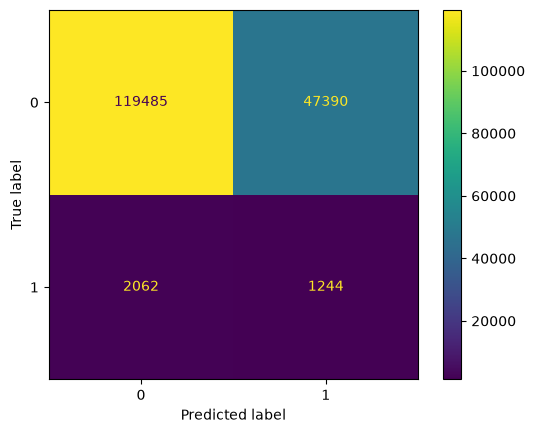

In [54]:
y_pred = rf.predict(X_test)

print(f"Analyzing scores for Random Forest:")
print(f"Accuracy_score: {accuracy_score(y_test, y_pred):.2f}")
precision, recall, fscore, _ = precision_recall_fscore_support(y_test, y_pred, average='binary')

print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F-score: {fscore:.2f}")
print(f"MSE: {mean_squared_error(y_test, y_pred):.4f}")

# Create the confusion matrix
matrix = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=matrix).plot();

In [55]:
#baseline and evaluate results
dummy = DummyClassifier(strategy='stratified', random_state=42) #baseline model

# Fit the baseline classifier on the training data
dummy.fit(X_train, y_train)

# Make predictions on the test data
y_pred = dummy.predict(X_test)

#Scores
print(f"Analyzing scores:")
print(f"Accuracy_score: {accuracy_score(y_test, y_pred):.2f}")
precision, recall, fscore, _ = precision_recall_fscore_support(y_test, y_pred, average='binary')

print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F-score: {fscore:.2f}")
print(f"MSE: {mean_squared_error(y_test, y_pred):.4f}")


Analyzing scores:
Accuracy_score: 0.96
Precision: 0.02
Recall: 0.02
F-score: 0.02
MSE: 0.0378


In [56]:
#create the model and set the parameters
log_model = LogisticRegression(
    random_state=42, #make it a reproducible analysis
    class_weight = "balanced", #To deal with the balance of the severe/not severe disproportion
    C = 1, #the strength of regularization (for overfitting)
    max_iter = 1000, #the amount of times the solver iterates when fitting
    l1_ratio = 0 #determines how the errors are weighted (l1:1 l2:0) will use l2
)

In [57]:
#fit the logistic classifier on test data
log_model.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

Analyzing scores for logistic Model
Accuracy_score: 0.67
Precision: 0.03
Recall: 0.47
F-score: 0.05
MSE: 0.3268
Confusion Matrix:


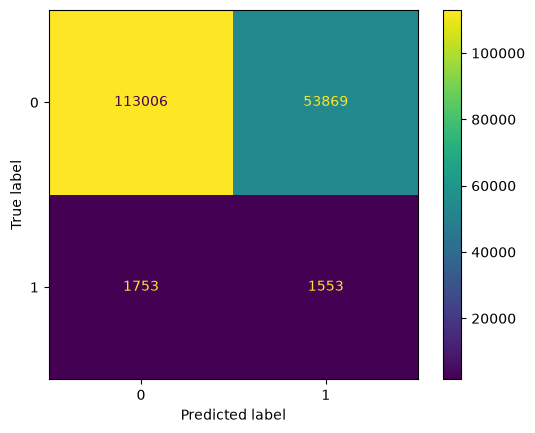

In [58]:
y_prediction = log_model.predict(X_test)

#Scores and Errors
print(f"Analyzing scores for logistic Model")
print(f"Accuracy_score: {accuracy_score(y_test, y_prediction):.2f}")
precision, recall, fscore, _ = precision_recall_fscore_support(y_test, y_prediction, average='binary')

print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F-score: {fscore:.2f}")
print(f"MSE: {mean_squared_error(y_test, y_prediction):.4f}")

#Creating the Confusion Matrix itself
confMatrix = confusion_matrix(y_test, y_prediction)
print("Confusion Matrix:")
disp = ConfusionMatrixDisplay(confusion_matrix=confMatrix, display_labels= log_model.classes_)
disp.plot()

## Visualization (The feature determined to be most significant when determining severe crashes)

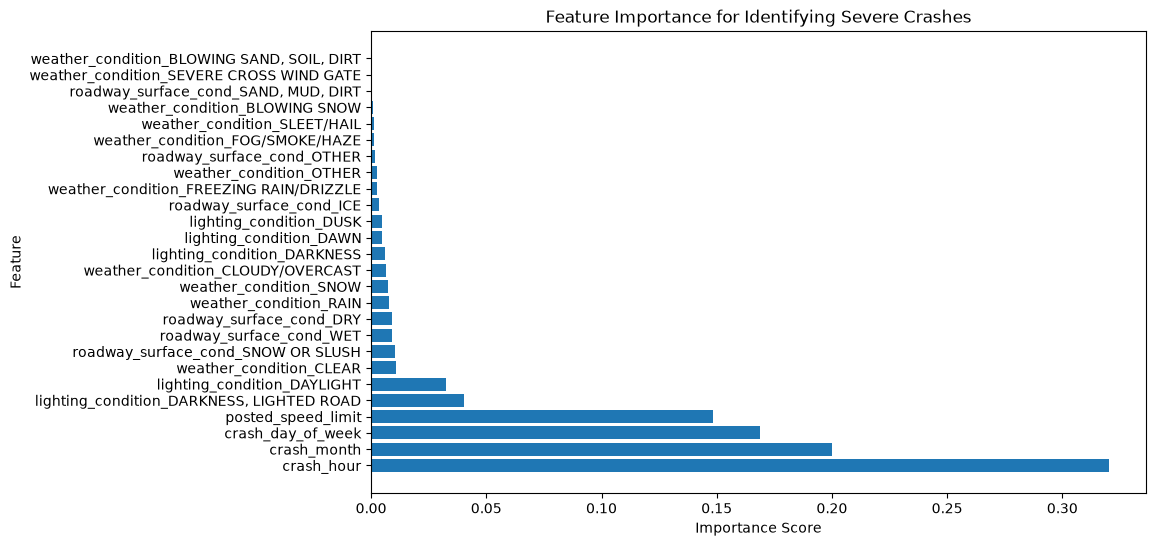

In [61]:
#Plotting
plt.figure(figsize=(10, 6))
plt.barh(feature_imp_df['Feature'], feature_imp_df['Importance'])
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.title('Feature Importance for Identifying Severe Crashes')
plt.show()